In [ ]:
import os, sys
cur_directory = os.getcwd()
save_directory = os.path.join(cur_directory, 'saved')

project_folder = ...
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [ ]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

from plot_preferences import *


2024-08-31 13:15:59.095427: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-08-31 13:15:59.467372: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-08-31 13:15:59.467492: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-08-31 13:15:59.554698: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-08-31 13:15:59.733082: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-08-31 13:15:59.736851: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [ ]:
stimuli = ['bushes', 'water', 'leaves', 'fish', 'opticflow']
# colors = np.array([[0.3 , 0.8 , 0.3 ],
#        [0.3 , 0.8 , 0.55],
#        [0.3 , 0.8 , 0.8 ],
#        [0.3 , 0.55, 0.8 ],
#        [0.3 , 0.3 , 0.8 ]])

colors = np.array([[0.8, 0.3, 0.7],
       [0.8, 0.5, 0.3],
       [0.5, 0.8, 0.3],
       [0.3, 0.8, 0.7],
       [0.3, 0.3, 0.8]])

data = [None]*len(stimuli)
data_dict = [None]*len(stimuli)

for j, stim in enumerate(stimuli):
    load_path = project_folder + f'/analyses/IB curves/saved/{stim}/all neurons small K large iter.dat'
    with open(load_path, 'rb') as f:
        data_dict[j] = pickle.load(f)
    data[j] = Namespace(**data_dict[j])

In [4]:
def process_trials(averages, stdevs, trial_axis=-1):
    trial_average = np.average(averages, axis=trial_axis)
    trial_variance = tools.cov_entrywise(averages, sum_axes=trial_axis)
    stdevs = np.sqrt(np.sum(stdevs**2, axis=trial_axis) + trial_variance)
    return trial_average, stdevs

average_test = [None]*len(stimuli)
stdevs_test = [None]*len(stimuli)
for j, stim in enumerate(stimuli):
    # average_test_shuffled, stdevs_test_shuffled = process_trials(data_shuffled.mi_averages_test, data_shuffled.mi_stdevs_test)
    # average_train_shuffled, stdevs_train_shuffled = process_trials(data_shuffled.mi_averages_train, data_shuffled.mi_stdevs_train)
    average_test[j], stdevs_test[j] = process_trials(data[j].mi_averages_test, data[j].mi_stdevs_test)

In [8]:
vars(data[0]).keys()

dict_keys(['samp_keep', 'mi_measurement_params', 'mov_ind', 'critic_params', 'train_fraction', 'mi_stdevs_test', 'opt_params', 'cg_params', 'mov_name', 'E_width', 'V_width', 'critic_type', 'N_training_repeats', 'V_E_buffer', 'mi_stdevs_train', 'mi_averages_test', 'mi_averages_train', 'coarse_grainer_type', 'meta_neuron_array'])

In [12]:
data[4].mi_measurement_params

{'quiet': True, 'batch_size': 500, 'N_batches': 500}

In [5]:
def unitize_range(x):
    return (x - np.min(x)) / (np.max(x) - np.min(x))

def linear_color(x, color_1, color_2):
    x = unitize_range(x)
    color_1 = np.array(color_1)
    color_2 = np.array(color_2)
    return [tuple((1 - y) * color_1 + y * color_2) for y in x]

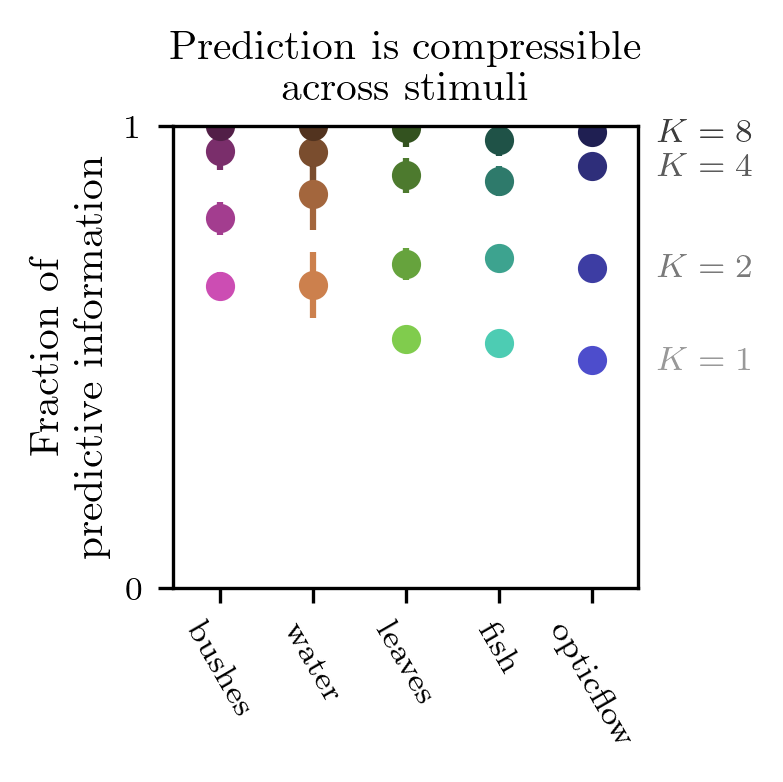

In [6]:
alp = 0.1
margin = 0.5
fig, ax = plt.subplots(figsize=[4*plot_scale,4*plot_scale], dpi=300)
N_K = 4

for j, stim in enumerate(stimuli):
    for i, K in enumerate(data[0].meta_neuron_array[:-1]):
        l = (N_K - i + 1) / (N_K + 1)
        I_max = np.amax(average_test[j])
        y = average_test[j][i] / I_max
        yerr = stdevs_test[j][i] / I_max
        # x = np.zeros(N_K) + j
        x = j
        # ax.semilogy(x, y, color=colors[j], label=stim)
        ax.errorbar(x, y, yerr, marker='o', color=colors[j] * l, label=stim)
        # ax.fill_between(x, y-yerr, y+yerr, color=(0,0,0,alp), linewidth=0)
        if j == 4:
            ax.text(4.7, y-0.02, f"$K={K}$", color=np.ones((3))*0.6*l)


ax.set_ylim(0,1)
ax.set_xlim( -margin, 4 + margin)
ax.set_xticks(np.arange(5))
ax.set_xticklabels(stimuli)
ax.tick_params(axis='x', labelrotation=-60)
ax.set_yticks([0,1])
ax.set_ylabel("Fraction of\n predictive information")
ax.set_title("Prediction is compressible\n across stimuli")    
# fig.savefig('./plots/compressibility across stim.svg', bbox_inches="tight")
fig.savefig('./plots/compressibility across stim.png', dpi=3000)

In [ ]:
load_path = project_folder + f'analyses/info decay vs K/saved/{stim}/1 2 4 8 93.dat'
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data2 = Namespace(**data_dict)

In [8]:
averages_test_2, stdevs_test_2 = process_trials(data2.mi_averages_test, data2.mi_stdevs_test)
averages_test_2[0] = average_test[4]
stdevs_test_2[0] = stdevs_test[4]

In [9]:
data2.V_E_buffer_array

array([ 0,  3,  6,  9, 12, 15, 18, 21, 24, 27, 29])

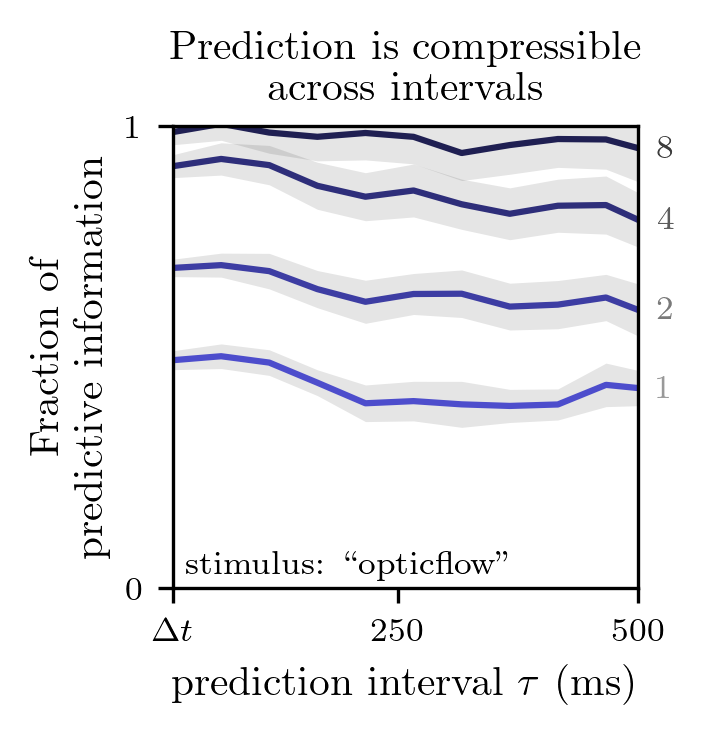

In [14]:
alp = 0.1
fig, ax = plt.subplots(figsize=[4*plot_scale,4*plot_scale], dpi=300)

dt = 1000 / 60
N_K = 4
j = 4
stim = 'opticflow'
for i, K in enumerate(data[0].meta_neuron_array[:-1]):
    l = (N_K - i + 1) / (N_K + 1)

    x2 = (data2.V_E_buffer_array + data2.V_width) * dt
    y = averages_test_2[:,i] / averages_test_2[:,-1]
    yerr = stdevs_test_2[:,i] / averages_test_2[:,-1]
    ax.plot(x2, y, color=colors[j]*l)
    ax.fill_between(x2, y-yerr, y+yerr, color=(0,0,0,alp), linewidth=0)
    # ax.text(520, y[-1]-0.02, f"$K={K}$", color=np.ones((3))*0.6*l)
    ax.text(520, y[-1]-0.02, f"${K}$", color=np.ones((3))*0.6*l)

# ax.text(520, 0, "$K$", color='k')
ax.text(30,0.03,'stimulus: ``opticflow"')
ax.set_title("Prediction is compressible\n across intervals")
ax.set_xlim(x2[0], x2[-1])
ax.set_xticks([dt, 250, 500]);
ax.set_xticklabels([r"$\Delta t$",250,500]);
ax.set_ylim(0,1)
ax.set_yticks([0,1])
ax.set_ylabel("Fraction of\n predictive information")
ax.set_xlabel(r'prediction interval $\tau$ (ms)')
# plt.savefig('./plots/compressibility across tau.svg', bbox_inches="tight")
plt.savefig('./plots/compressibility across tau.png', dpi=3000)

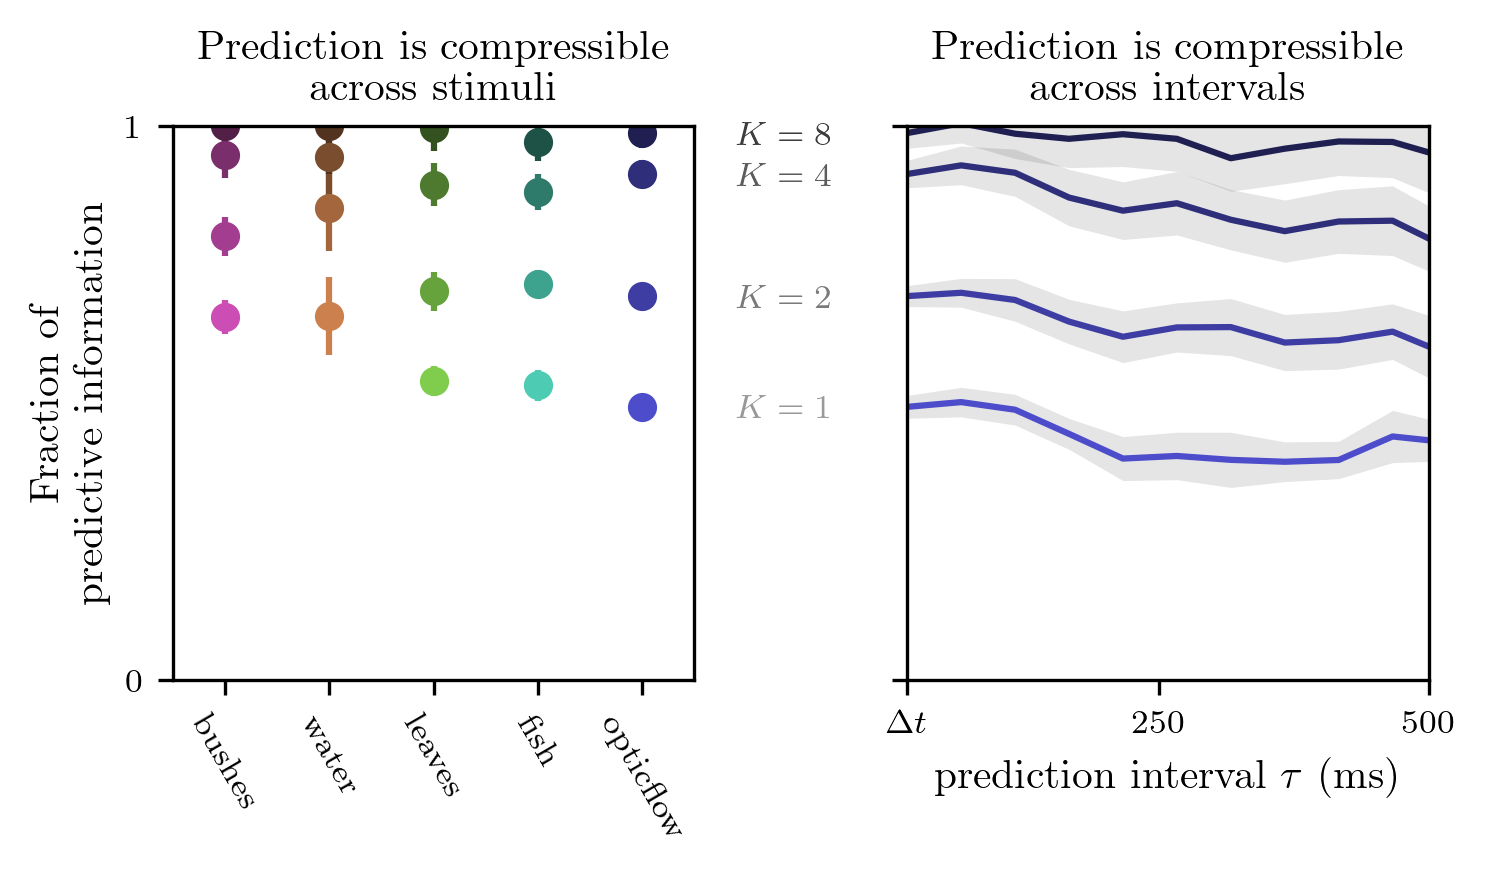

In [ ]:
# plot_scale = 0.6
alp = 0.1
fig, ax = plt.subplots(ncols=3, figsize=[9*plot_scale,4*plot_scale], dpi=300, sharey=True, width_ratios=[4,0.5,4])

dt = 1000 / 60
N_K = 4

for j, stim in enumerate(stimuli):
    for i, K in enumerate(data[0].meta_neuron_array[:-1]):
        l = (N_K - i + 1) / (N_K + 1)
        I_max = np.amax(average_test[j])
        y = average_test[j][i] / I_max
        yerr = stdevs_test[j][i] / I_max
        # x = np.zeros(N_K) + j
        x = j
        # ax[0].semilogy(x, y, color=colors[j], label=stim)
        ax[0].errorbar(x, y, yerr, marker='o', color=colors[j] * l, label=stim)
        # ax[0].fill_between(x, y-yerr, y+yerr, color=(0,0,0,alp), linewidth=0)
        if j == 4:
            ax[0].text(4.9, y-0.02, f"$K={K}$", color=np.ones((3))*0.6*l)


ax[0].set_ylim(0,1)
ax[0].set_xlim( -margin, 4 + margin)
ax[0].set_xticks(np.arange(5))
ax[0].set_xticklabels(stimuli)
ax[0].tick_params(axis='x', labelrotation=-60)
ax[0].set_yticks([0,1])
ax[0].set_ylabel("Fraction of\n predictive information")
ax[0].set_title("Prediction is compressible\n across stimuli")

j = 4
stim = 'opticflow'
for i, K in enumerate(data[0].meta_neuron_array[:-1]):
    l = (N_K - i + 1) / (N_K + 1)

    x2 = (data2.V_E_buffer_array + data2.V_width) * dt
    y = averages_test_2[:,i] / averages_test_2[:,-1]
    yerr = stdevs_test_2[:,i] / averages_test_2[:,-1]
    ax[2].plot(x2, y, color=colors[j]*l)
    ax[2].fill_between(x2, y-yerr, y+yerr, color=(0,0,0,alp), linewidth=0)
ax[1].axis('off')
ax[2].set_title("Prediction is compressible\n across intervals")
ax[2].set_xlim(x2[0], x2[-1])
ax[2].set_xticks([dt, 250, 500]);
ax[2].set_xticklabels([r"$\Delta t$",250,500]);
ax[2].set_xlabel(r'prediction interval $\tau$ (ms)')

plt.savefig('./plots/compressibility.svg', bbox_inches="tight")